In [1]:
import matplotlib.pyplot as plt

import sys
sys.path.append('../src')

from constants import DATASETS, LABEL_TYPES, RHYTHM_TYPES
from data import load_dyads, load_units
from metrics.thresholds import RHO, TAU
from viz.dyads_plot import DyadsPlotter, plot_absolute_criterion, plot_relative_criterion
from viz.timeline import plot_compact_timeline, setup_label_colors
from viz.utils import savefig, set_mpl_style, subplot_title, ylabel_annot
from viz.density import plot_bilateral_densities
set_mpl_style()

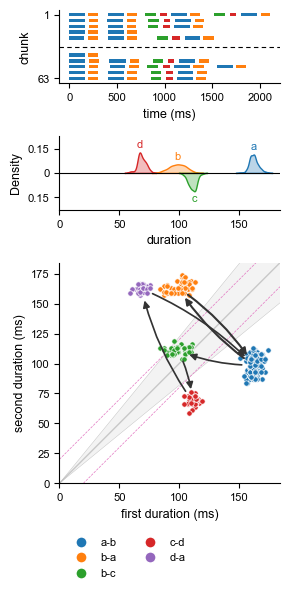

In [2]:
def plot_example(units, dyads, figsize=(3, 6), axs=None, normalize_height=False, rows=None):
    if axs is None:
        _, axs = plt.subplots(3, 1, figsize=figsize, height_ratios=[1, 1, 3])
    else:
        assert len(axs) == 3
    (ax0, ax1, ax2) = axs
    ax2.sharex(ax1)

    colors = setup_label_colors(units)

    # Timeline
    plot_compact_timeline(units, ax=ax0, colors=colors, show_labels=False, rows=rows)

    # Densities
    plot_bilateral_densities(
        units, ax=ax1, show_xticklabels=True, normalize_height=normalize_height,
        colors=colors, show_labels=True
    )
    
    # Phase plot
    plt.sca(ax2)
    plot = DyadsPlotter(
        dyads[["duration_1", "duration_2"]].to_numpy(),
        dyads["label"],
        dyads["chunk_idx"],
    )
    plot.scatter()
    plot.transition_network(show_legend=False)
    plot.phase_axes(
        xlabel="first duration (ms)", 
        ylabel="second duration (ms)",
        square=True,
    )
    plot_relative_criterion(RHO, ax=ax2, lw=.25, color='.7', alpha=.15)
    plot_absolute_criterion(TAU, ax=ax2, lw=.5, color='C6', ls="--", fill=False)
    plot.legend(below=True, ncols=2)

def load_example(dataset_id, rhythm_type, bird_id):
    """One bird's units and dyads, with its labels in a 'label' column: the
    annotated labels where the dataset has them, the predicted ones otherwise."""
    spec = DATASETS[dataset_id]
    bird_col = spec['bird_id_col']
    label_col = LABEL_TYPES['annot' if 'annot' in spec['label_types'] else 'pred']
    units = load_units(dataset_id, rhythm_type)
    dyads = load_dyads(dataset_id, rhythm_type, bird_id_col=bird_col)
    units = units[units[bird_col] == bird_id]
    dyads = dyads[dyads[bird_col] == bird_id]
    return units.assign(label=units[label_col]), dyads.assign(label=dyads[label_col])

def show_example(dataset_id, rhythm_type, bird_id, **kwargs):
    plot_example(*load_example(dataset_id, rhythm_type, bird_id), **kwargs)

show_example('ns', 'syll_dur', 'ns-4635')
plt.tight_layout()

In [3]:
# Three columns span 174 mm (6.85 in)
COL_WIDTH = 6.85 / 3
FONT_RC = {'xtick.labelsize': 7, 'ytick.labelsize': 7, 'axes.labelsize': 7, 'legend.fontsize': 7}

def show_examples(panels, share_phase_axes=False):
    """One column per panel, each a (dataset_id, rhythm_type, bird_id) tuple,
    or None for an empty 'NA' column."""
    with plt.rc_context(FONT_RC):
        return _show_examples(panels, share_phase_axes)

def _show_examples(panels, share_phase_axes):
    fig, axs = plt.subplots(
        3, len(panels), height_ratios=[1, 1, 3], figsize=(COL_WIDTH * len(panels), 5.6), squeeze=False
    )
    shown = [panel for panel in panels if panel is not None]
    show_dataset = len({dataset_id for dataset_id, _, _ in shown}) > 1

    # When all panels show one bird, give every timeline the same rows and
    # time axis, so the same chunks line up across panels
    rows = None
    if len({(dataset_id, bird_id) for dataset_id, _, bird_id in shown}) == 1:
        rows = sorted(set().union(*(
            load_example(*panel)[0]['chunk_idx'] for panel in shown
        )))
        for ax in axs[0, 1:]:
            ax.sharey(axs[0, 0])
            ax.sharex(axs[0, 0])

    for i, panel in enumerate(panels):
        if panel is None:
            for ax in axs[:, i]:
                ax.set_axis_off()
                ax.annotate('NA', (0.5, .5), color='.7')
            continue
        dataset_id, rhythm_type, bird_id = panel
        title = RHYTHM_TYPES[rhythm_type]['label']
        if show_dataset:
            title = f'{dataset_id.upper()}: {title}\n({bird_id})'
        subplot_title(i, title, ax=axs[0, i], y=1.2)
        show_example(dataset_id, rhythm_type, bird_id, axs=axs[:, i], rows=rows)

    if share_phase_axes:
        phase_axs = [ax for ax in axs[2] if ax.axison]
        lim = max(max(ax.get_xlim()[1], ax.get_ylim()[1]) for ax in phase_axs)
        for ax in phase_axs:
            ax.set_xlim(0, lim)
            ax.set_ylim(0, lim)

    # Only the leftmost column gets y-axis labels
    for ax in axs[:, 1:].flat:
        ax.set_ylabel('')

    ylabel_annot('1. Timeline', y=.83)
    ylabel_annot('2. Unit durations', y=.6)
    ylabel_annot('3. Phase plot', y=.33)

    plt.tight_layout(w_pad=0.5)
    return fig

def save_example(name):
    savefig(name, bbox_inches='tight', pad_inches=0.02)
    plt.close()


## BVS

Syllable, element and gap units of one bird, for each unit type: durations (Figure 1), IOIs (Figure S7a) and boundaries (Figure S7b). Gaps have no boundaries.

In [4]:
BVS_BIRD = 'bvs-669'
for fig, kind in [('fig1', 'dur'), ('figS7a', 'ioi'), ('figS7b', 'bound')]:
    show_examples([
        ('bvs', f'syll_{kind}', BVS_BIRD),
        ('bvs', f'elem_{kind}', BVS_BIRD),
        ('bvs', f'gap_{kind}', BVS_BIRD) if kind != 'bound' else None,
    ], share_phase_axes=(fig == 'fig1'))
    save_example(f'{fig}-{BVS_BIRD}-{kind}')


## NS

The same bird's syllables (IOIs, durations, boundaries; Figure S7c) and gaps (durations, IOIs; Figure S7d). NS has no element annotations.

In [5]:
NS_BIRD = 'ns-4306'
show_examples([('ns', rhythm_type, NS_BIRD) for rhythm_type in ['syll_ioi', 'syll_dur', 'syll_bound']])
save_example(f'figS7c-{NS_BIRD}-syll')

show_examples([('ns', rhythm_type, NS_BIRD) for rhythm_type in ['gap_dur', 'gap_ioi']])
save_example(f'figS7d-{NS_BIRD}-gap')


## RT, BWPS and BWPS-clean

Syllable IOIs of one bird per dataset (Figure S7e). These datasets have no annotated labels, so the predicted ones are shown; RT birds are also predicted.

In [6]:
show_examples([
    ('rt', 'syll_ioi', 'rt-pred-006'),
    ('bwps', 'syll_ioi', 'bwps-bl10or50'),
    ('bwps-clean', 'syll_ioi', 'bwps-clean-bl10or50'),
])
save_example('figS7e-rt-bwps-syll_ioi')
